# Week 6 - Trees

# 6.2 - Data Prep

In [1]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np

import seaborn as sns

from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
# GET DATA
#    import pandas as pd

data_url = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'

df = pd.read_csv(data_url)

In [3]:
# PREVIEW DATA
# df.head()

In [4]:
# PREPARE DATA
#   STANDARDIZE COLUMN NAMES
df.columns = df.columns.str.lower()


In [5]:
# REVIEW COLUMN NAMES AND DATATYPES
# df.dtypes

In [6]:
# CREATE A LIST OF CATEGORICAL COLUMN NAMES
# categorical_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()  
# categorical_columns

In [7]:
# CREATE A LIST OF CATEGORICAL COLUMN NAMES
numerical_columns = df.select_dtypes(include="number").columns.tolist()
# numerical_columns

In [8]:
# SHOW FREQUENCE OF ALL UNIQUE VALUES PRESENT ON CATEGORICAL COLUMNS
# for c in categorical_columns:
#    print(df[c].value_counts())

In [9]:
# DESCRIBE STATISTICAL ATTRIBUTES OF EACH NUMERICAL COLUMN
# for n in numerical_columns:
#    print(df[n].describe)
    

In [10]:
# df.status.value_counts()

So 3200 customers paid back their loans, 1254 defaulted, and there's one record with the value 0 - an unknown status. We use dictionaries and the Pandas map method to translate the numbers into strings:

In [11]:
# MANUALLY CREATE A FINAL LIST OF CATEGOTICAL FEATURES
categorical_columns = ["status","home","marital","records","job"]

# MAP status_values CODES TO TEXT
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

# MAP home_values CODES TO TEXT
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

# MAP marital_values CODES TO TEXT
marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

# MAP records_values CODES TO TEXT
records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

# MAP job_values CODES TO TEXT
job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [12]:
# PREVIEW DATAFRAME TO CONFIRM DATA PREPARATION IS SUFFICIENT TO MAKE IT USABLE
# df.head()

In [13]:
# CHECK FOR MISSING VALUES
#   MISSING VALUES PRESENT AS '99999999.0' IN THIS DATASET
# df.describe().round()

In [14]:
# CONVERT MISSING VALUES TO 'NaN'
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

# PREVIEW MODIFIED DATAFRAME
df.describe().round()

#   NOTE: All 'count' ROW VALUES SHOULD BE THE SAME, COLUMNS WITH MISSING VALUES WILL DIFFER
#         ALL '99999999.0' HAVE NOW BEEN REMOVED, YOU CAN SEE THIS IN THE 'max' ROW

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [15]:
# THERE IS ONLY ONE ROW WITH AN 'unk' STATUS 
#  WE ONLY CARE ABOUT THE 'okay' AND 'default' CLASSES
#  WE SHOULD DROP THE 'unk' ROW FROM OUT DATASET

df = df[df.status != 'unk'].reset_index(drop=True)

In [16]:
# SPLIT DATASET
# from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df,            test_size=0.2,  random_state=11)
df_train, df_val       = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [17]:
# RESET THE INDEX VALUES FOR EACH DATAFRAME
df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(  drop=True)
df_test  = df_test.reset_index( drop=True)

## Preparing the target variable
The models give us a probability, so the target needs to be a number. We encode status: 0 for ok, 1 for default:


In [18]:
# SET TARGET COLUMN
target_column = "status"

# CREATE TARGET VECTOR
y_train = (df_train[target_column] == 'default').astype('int').values
y_val   = (df_val[target_column]   == 'default').astype('int').values
y_test  = (df_test[target_column]  == 'default').astype('int').values

# DROP TARGET FROM THE FEATURE MATRIX
for df in (df_train, df_val, df_test):
    df.drop(columns=[target_column], inplace=True)

# 6.2 - Decision trees
In this unit we train our first decision tree with scikit-learn on the credit scoring data, see what overfitting looks like, and learn how to control the size of a tree. \
 \ 
## What a decision tree looks like
At its core, a decision tree is just a set of if/else rules. For our credit risk problem, we could write one by hand:

```
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'
```

Let's take one customer from the training data and check what the rules say about them:


In [19]:
# DEFINE assess_risk() FUNCTION
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'
            
# EVALUATE RISK            
xi = df_train.iloc[0].to_dict()
assess_risk(xi)


'ok'

Writing rules by hand doesn't scale. The point of the decision tree algorithm is that it learns these rules from data automatically.
# Training a decision tree

We use DecisionTreeClassifier from scikit-learn. \
The features are mixed: numeric columns and categorical ones we encoded as strings. \
We turn each row into a dictionary, \
fill the missing values with 0, and \
use DictVectorizer to convert the dictionaries into a feature matrix:

In [20]:
from sklearn.tree               import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics            import roc_auc_score
from sklearn.tree               import export_text

In [21]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

dv          = DictVectorizer(sparse=False)
X_train     = dv.fit_transform(train_dicts)

**DictVectorizer**
* one-hot encodes the categorical features
  - creates columns like job=partime and records=no 
 
and leaves the numeric ones unchanged.

In [22]:
# TRAIN THE DECISION TREE
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [23]:
# REVIEW MODEL AGAINST THE VALIDATION DATASET
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val     = dv.transform(val_dicts)

y_pred    = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.6553274321280667

In [24]:
# print(X_val, y_val)

In [25]:
# !!! THERE IS A PROBLEM HERE - AUC SHOULD BE '0.6548400377806302' !!!
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

AUC of 1.0 on training but 0.65 on validation: the tree memorized the training data. \
It learned one specific rule per customer, so on the customers it has seen it's perfect \
these rules don't generalize to unseen customers. \
\
This is overfitting: memorizing the data but failing to generalize. \
\
The reason is that we let the tree grow without limits, so it became very deep: \
it kept splitting until every leaf was pure. 
## Controlling the size of the tree
We can restrict the depth of the tree with the max_depth parameter. \
A shallow tree cannot memorize each customer - it has to learn broader rules:

In [26]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [27]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train:', auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val:', auc)

train: 0.7054989859726213
val: 0.6685264343319367


## Looking inside the tree

To see the rules the tree learned, we use export_text:



In [28]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- class: 1
|--- records=yes >  0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0



A Decision Tree with only one question is called a **'DECISION STUMP'** \
\
The question is: 
- how does the learning algorithm decide which condition and
- which threshold to use at each split? 

# Tree vocabulary

First, the names for the parts of a tree:

    A **node** contains a condition, for example assets > 3000.
    Two **branches** go out of it: one for "true" and one for "false".
    The node at the top is the **root**; every node except the leaves is a **parent** of two other nodes.
    The nodes at the bottom are **leaves (decision nodes)**: this is where the tree stops and the prediction is made.
    The **depth of a tree** is the number of levels - the length of the longest path from the root to a leaf.

To understand how the algorithm learns such a tree, we take a small toy dataset instead of the full credit scoring data.
Finding the best split for one column \
 \
We take eight customers with one feature, assets, and the target, status:

In [30]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'status'])

In [32]:
# BUILD A DECISION STUMP WITH ONE CONDITION (e.g., assets > T)

# DEFINE THRESHOLDS (T) TO EVALUATE WHEN CONSIDERING APPROPRIATE T VALUES
Ts = [0, 2000, 3000, 4000, 5000, 8000]

In [33]:
T        = 4000
df_left  = df_example[df_example.assets <= T]
df_right = df_example[df_example.assets > T]

display(df_left)
print(df_left.status.value_counts(normalize=True))
display(df_right)
print(df_right.status.value_counts(normalize=True))

,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64


# ADD ANOTHER FEATURE

In [35]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000,  500, 'ok'],
    [3000, 2000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'debt', 'status'])

In [36]:
# DEFINE THRESHOLDS TO TEST
thresholds = {
    'assets': [0, 2000, 3000, 4000, 5000, 8000],
    'debt': [500, 1000, 2000]
}

for feature, Ts in thresholds.items():
    print('#####################')
    print(feature)
    for T in Ts:
        print(T)
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        display(df_left)
        print(df_left.status.value_counts(normalize=True))
        display(df_right)
        print(df_right.status.value_counts(normalize=True))

        print()
    print('#####################')

#####################
assets
0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64

3000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
7,3000,2000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok


status
ok         0.8
default    0.2
Name: proportion, dtype: float64

4000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
5,4000,1000,ok
7,3000,2000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
3,5000,1000,ok
4,5000,1000,ok
6,9000,500,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64

5000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.5
ok         0.5
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
6,9000,500,ok


status
default    0.5
ok         0.5
Name: proportion, dtype: float64

8000


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64


,assets,debt,status
6,9000,500,ok


status
ok    1.0
Name: proportion, dtype: float64

#####################
#####################
debt
500


,assets,debt,status
6,9000,500,ok


status
ok    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64

1000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok


status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
7,3000,2000,default


status
default    1.0
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64

#####################


For debt, the best split gives an average impurity of 16% - worse than the 10% we got with assets. \
\
So the best split overall is still assets > 3000. With more features we would simply add more rows to this comparison.\

```
# PSEUDO CODE TO FIND THE BEST SPLIT THRESHOLD
FOR each feature in FEATURES:
    FIND all thresholds for the feature
    FOR each threshold in thresholds:
        SPLIT the dataset using "feature > threshold" condition
        COMPUTE the impurity of this split
SELECT the condition with the LOWEST IMPURITY
```
The misclassification rate is not the only impurity measure. \
Scikit-learn uses more sensitive criteria: Gini impurity and entropy. \
For regression trees the equivalent is MSE. \
\
The idea stays the same: pick the split with the lowest impurity. \
\
And while we looked at classification here, decision trees can also solve regression problems.

## Stopping criteria

After the root is split, the algorithm applies the same procedure recursively to the left and right sides. \
\
When does it stop?

- The group is already pure - the misclassification rate is 0%, no point in splitting further.
- The tree reached the maximum depth limit - controlled by max_depth.
- The group is too small to split - controlled by min_samples_leaf.
- The maximum number of leaves (decision nodes) was reached.

These stopping criteria are what keep a tree from overfitting.

    If the stopping criteria are not met (max depth not reached, groups large enough and not pure), repeat for the left side and the right side.


## Notes

This lesson first reviews the topics learned in the previous lesson about how to train a decision tree using scikit-learn, and handle a decision tree model not generalizing well due to overfitting of the data.

In this lesson, we learn about how to best split a decision tree and different classification criteria that can be used to split a tree. We dive deep in an example, splitting trees with misclassification criteria. Additionally, different stopping criteria to break the iterative tree split are discussed.

- **Structure of a decision tree**: A decision tree is a data structure composed of nodes (which contain conditions) and branches (which represent the values for a condition: True or False). The tree starts with a root node, which is the parent of two other nodes, and each of these nodes can also be the parent of others. At the last level of the tree, there are terminal nodes, also called leaves.

- **Depth of a decision tree**: The depth of a tree is the number of levels it has, or simply the length of the longest path from the root node to a leaf node.

- **Rules & Conditions, Thresholds**: The learning algorithm for a decision tree involves determining the best conditions to split the data at each node in order to achieve the best possible classifier. When there are many features, the algorithm considers each feature with its optimized threshold to determine the best feature for splitting at a particular node. In essence, at each node, the algorithm evaluates all possible thresholds for every feature and calculates the resulting misclassification rate. It then selects the condition (feature and threshold) that yields the lowest impurity.

- **Misclassification rate**: After each split, the goal is to divide the data into two sets that are as pure as possible. This means that the data within each set should belong predominantly to either one class, or the other. Another way to describe this is to aim for the lowest possible misclassification rate (impurity). The misclassification rate is a weighted average of the error rates obtained after splitting the data into two sets. The predicted class for each set is determined by the majority class present in this set.

- **Impurity criteria**: Common misclassification rate measurements are GINI Impurity and Entropy. It is also possible to use MSE for regression problems.

- **Decision trees can be used to solve regression problems**: While we focused on decision tree classifiers, it's important to note that decision trees can also be applied to regression problems using decision tree regressors.

- **Stopping Criteria**: The process of recursively splitting the data at each child node eventually stops based on certain stopping criteria. These criteria prevent the model from overfitting and include:
        The group is already pure: 0% impurity.
        The maximum depth has been reached.
        The group is smaller than the minimum size set for groups.
        The maximum number of leaves/terminal nodes has been reached.

**Decision Tree Learning Algorithm in a Nutshell**

    At a node, find the best split.
    Stop if max_depth is reached.
    For each child node, if the node is sufficiently large and not pure, repeat the process from the beginning.


# 6.5 - Which parameters to tune

**DecisionTreeClassifier** has many parameters - criterion, which is the **impurity** measure, **max_depth**, **min_samples_leaf**, and others. The two that matter most are:

    **max_depth** - the maximum number of levels. It limits how specific the rules can get.
    **min_samples_leaf** - the minimum number of samples in a leaf. It prevents the tree from creating leaves that cover just one or two customers.

**Tuning** means selecting the values that give the best score on the validation set - AUC in our case.
Selecting max_depth \
 \
We start with max_depth alone. We try depths from 1 to 20, plus None (no limit), and record the validation AUC for each:

In [39]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

print('depth\tauc')
print("------------------------")

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

depth	auc
------------------------
   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.766
   6 -> 0.747
  10 -> 0.678
  15 -> 0.660
  20 -> 0.651
None -> 0.661


Depths 4, 5 and 6 are the best (AUC around 0.76). Trees that are too shallow underfit; deep trees overfit and end up worse than the simple ones. \
# Adding min_samples_leaf

Now we take the promising **depth** values - 4, 5 and 6 - and for each of them try several values of **min_samples_leaf**. \
We store the results as tuples in a list:

In [41]:
scores = []

for depth in [4, 5, 6]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

Then we put the scores into a dataframe:

In [42]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

In [46]:
df_scores

,max_depth,min_samples_leaf,auc
0,4,1,0.761283
1,4,5,0.761283
2,4,10,0.761283
3,4,15,0.763726
4,4,20,0.760910
5,4,500,0.679842
6,4,100,0.755937
7,4,200,0.747260
8,5,1,0.766938
9,5,5,0.768173


The sorted dataframe is hard to scan. It's easier to reshape it: rows for min_samples_leaf, columns for max_depth, and the AUC in the cells. That's what the pivot method does:

In [44]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc              
max_depth             4      5      6
min_samples_leaf                     
1                 0.761  0.767  0.758
5                 0.761  0.768  0.759
10                0.761  0.762  0.778
15                0.764  0.772  0.786
20                0.761  0.774  0.774
100               0.756  0.763  0.776
200               0.747  0.759  0.768
500               0.680  0.680  0.680

Even easier to read as a heatmap - the best cell is the lightest one: \
 \
 `sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")` draws a Seaborn heatmap from `df_scores_pivot`.

- `df_scores_pivot`: the table of values shown as colored cells.
- `annot=True`: writes each cell’s value inside the cell.
- `fmt=".3f"`: formats those annotations to three digits after the decimal point, such as `0.842`.

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

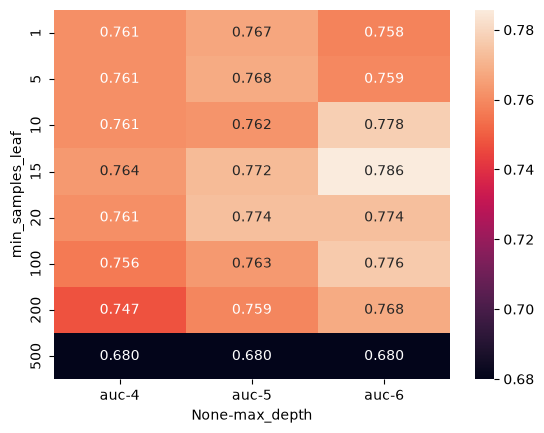

In [47]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

The best combination is `max_depth=6` and `min_samples_leaf=15`, with an `AUC` of `0.785` - better than anything we saw when tuning **max_depth** alone. \
 \
Note that we only searched depths 4-6 for the second parameter. \
On a large dataset it would be too slow to try every combination, so we first select **max_depth** and then tune the rest. On this small dataset we could afford to check more combinations - and if we did, other close pairs would show up. \
\
It's a good habit to start with a coarse search and refine it.

# The final tree

Lets train the tree with the tuned parameters and look at the rules it learned:

In [48]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- assets <= 4250.00
|   |   |   |   |--- income <= 20.00
|   |   |   |   |   |--- seniority <= 1.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- seniority >  1.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  20.00
|   |   |   |   |   |--- expenses <= 71.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- expenses >  71.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  4250.00
|   |   |   |   |--- debt <= 1600.00
|   |   |   |   |   |--- seniority <= 2.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- seniority >  2.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- debt >  1600.00
|   |   |   |   |   |--- class: 1
|   |   |--- income >  74.50
|   |   |   |--- seniority <= 5.50
|   |   |   |   |--- amount <= 1330.00
|   |   |   |   |   |--- assets <= 3326.00
|   |   |   |   |   |   |--- clas

This tree is still readable, unlike the unlimited one from before: it starts with records, then looks at seniority, amount, price and assets to decide whether a customer is likely to default.

One caution: when you scan the results, watch out for parameter values that don't make sense, like nan creeping into the grid. A combination can show a good score by accident - check that the values you pick actually control the size of the tree the way you intend.
Notes

In this lesson, we will discuss about different parameters used to control a Decision Tree (DT). Two of them, max_depth and min_samples_leaf have a greater importance than the others. We will further see how we first tune max_depth parameter and then move to tuning other parameters will help. After that, a dataframe will be created with all possible combinations of max_depth, min_sample_leaf and the auc score corresponding to them. These results will be visualized using a heatmap by pivoting the dataframe to easily determine the best possible max_depth and min_samples_leaf combination. Finally, the DT will be retrained using the identified parameter combination. The DT so trained will be viewed as a tree diagram, for visualizing decision rules.
## Steps

    **Fine-Tuning Process**: iterate to find optimal parameter settings.
        Start by tuning max_depth with various values to determine a subset of optimal depths.
        Then, using this subset, fine-tune the model further by exploring different min_samples_leaf values.

    This method is computationally efficient for large datasets, though it may not be optimal for smaller ones.

    **Heatmaps for Visualization**: Store the scores (e.g., AUC) obtained during tuning in a pivot table, and create a heatmap with seaborn to easily identify high score areas, which helps pinpoint the optimal **max_depth** and **min_samples_leaf** combination.

NB: Choose parameter values that effectively control the tree's size and avoid values like 'nan' (Not a Number), even if they seem to lead to better scores.
Importance of **max_depth** and **min_samples_leaf**

    **Controlling Overfitting**: these parameters play a critical role in preventing overfitting.
        **max_depth** limits the tree's complexity, preventing it from growing too deep and memorizing the training data.
        **min_samples_leaf** ensures that leaf nodes have a sufficient number of samples, reducing the chance of creating nodes that are too specific to the training data.

    **Impact on Bias and Variance**: They also affect the model's bias and variance.
        Increasing **max_depth** and decreasing **min_samples_leaf** can lead to a more complex model with lower bias but higher variance.
        Decreasing **max_depth** and increasing **min_samples_leaf** results in a simpler model with higher bias but lower variance.

It's then important to find the right balance between **max_depth** and **min_samples_leaf** to achieve optimal model performance. This involves a trade-off between bias and variance, and the best values depend on the specific dataset and problem.

# 6.6 - Ensemble learning and random forest

In this unit we combine many decision trees into one model. We start with the idea behind it - asking a board of experts instead of trusting a single one - then build a random forest with scikit-learn and tune its three main parameters. \

## Board of experts

So far we score a loan application with a single decision tree: the features of the client go in, the tree outputs the probability of default, and the bank uses this score to approve or reject the application. \
 \
Instead of one expert, imagine a board of five experts. When a client submits an application, it goes to each of them. Every expert looks at the application and decides: approve or reject. The final decision is made by majority vote. The idea is that the collective opinion of five experts is more reliable than the opinion of one.

Each model receives a random subset of features \
 \
We can do the same with models. Instead of five people, we have five models \
 \
g1, g2 and so on - and each of them returns its probability of default. To combine them, we take the average of these probabilities:

```
(1/n) * (p1 + p2 + ... + pn)
```
\
Combining several models this way is called ensembling, and the individual models are often called "weak learners": each one alone is not great, but together they are stronger than any single model.
Random forest

When the models we ensemble are decision trees, the ensemble is called a **random forest**. But it cannot be just any group of trees - the trees need to be different from each other. \
 \
If we simply train the same tree several times on the same data with the same parameters, we get identical trees that produce identical predictions, and averaging them gives exactly the same result as a single tree. \
 \
The "random" in random forest is what makes the trees diverse: 
- each tree gets a random subset of features, and - depending on the bootstrap parameter
- a randomly resampled copy of the training data. \
\
To see the idea, suppose we have three features: **assets**, **debt** and **price**, and we train three trees. \
\
The first tree may see assets and debt, \
the second assets and price, and \
the third debt and price. \
\
Each tree gives its own prediction - p1, p2 and p3 - and the final prediction is the average: \
```1/3 (p1 + p2 + p3)```


In scikit-learn, random forest lives in the ensemble package. Let's take our credit scoring data and train a random forest with a varying number of trees - from 10 to 200 with a step of 10 - and see how the number of trees affects the AUC on validation:

In [51]:
from sklearn.ensemble import RandomForestClassifier

scores = []

print('depth\tauc')
print("------------------------")
for n in range(10, 201, 10):
    rf = RandomForestClassifier(
        n_estimators=n, 
        random_state=1
    )
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))
print("done")

depth	auc
------------------------
done


Then we put the scores into a dataframe and plot them:

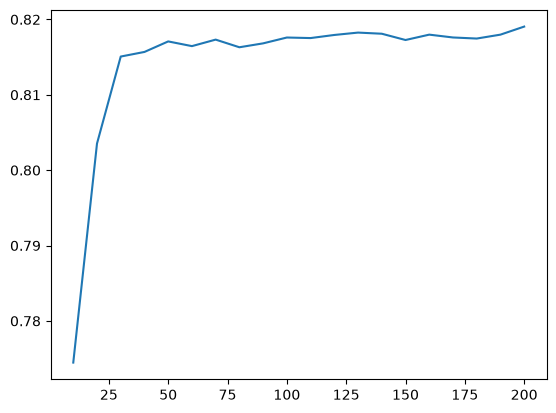

In [52]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
plt.plot(df_scores.n_estimators, df_scores.auc)

The curve grows quickly at the beginning and then stabilizes: \
after some number of trees, adding more of them does not improve the score. Still, more trees never hurt the quality \
the curve stays flat \
\
the main cost of extra trees is training time, not accuracy. \
\
This is why `n_estimators` is usually set to "as many as you can afford", and we tune the other parameters first.
## Tuning max_depth

Now let's tune max_depth, the maximum depth of each tree in the forest. \
We use the same loop, but this time we try three values of `max_depth` - 5, 10 and 15 - and for each of them we again iterate over the number of trees:

In [54]:
scores = []

# d = maximum depth of each tree
# n = number of trees

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

To compare the three depths, we plot each of them as a separate line:

    The below code plots `auc` against `n_estimators` using Matplotlib:

    `df_subset.n_estimators` provides the x-values.\

    `df_subset.auc` provides the y-values.\

    `label='max_depth=%d' % d` creates a legend label by inserting the value of d. For example, if d is 5, the label is "max_depth=5".\
\
    To display that label in a legend, call plt.legend() after plotting.

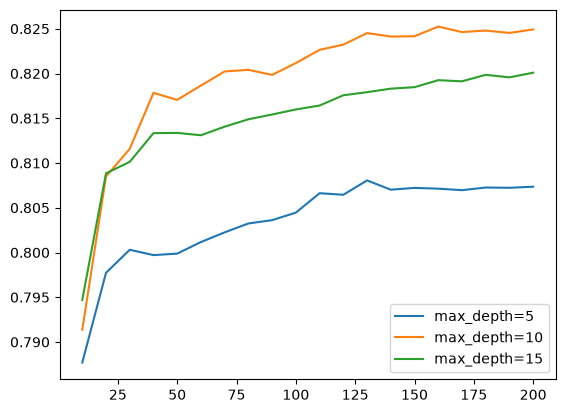

In [56]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

# d = maximum depth of each tree

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, 
             df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

The curves for `max_depth=10` and `max_depth=15` are clearly better than the one for `max_depth=5`, and `max_depth=10` is the best of the three. So we fix it:
\
`max_depth = 10`
\
Tuning `min_samples_leaf`\
\
The third parameter is `min_samples_leaf` - the minimal number of observations allowed in a leaf of a tree. We repeat the same procedure: keep max_depth fixed at 10 and try `min_samples_leaf` of `1, 3, 5, 10 and 50`, each combined with a varying number of trees:

In [63]:
scores = []

# s = minimum number of leaf samples
# d = maximum depth of each tree
# n = number of trees

max_depth = 10

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier( n_estimators     = n,
                                     max_depth        = max_depth,
                                     min_samples_leaf = s,
                                     random_state     = 1
                                   )
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

And plot all five curves, giving each value its own color:

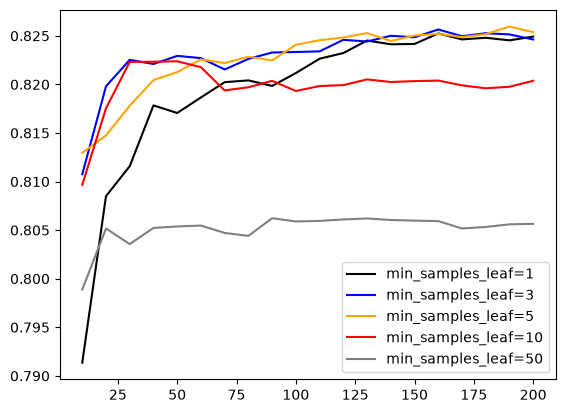

In [64]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, 
             df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s
            )

plt.legend()


The curves with small values - 1, 3 and 5 - are close to each other at the top, while 10 and especially 50 are worse. We take `min_samples_leaf=3`: \
\
`min_samples_leaf = 3`

## The final model

With the parameters selected, we train the final random forest with 200 trees:

In [65]:

max_depth = 10
min_samples_leaf = 3

rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

There are other useful parameters for random forest - for example max_features, which controls the size of the random feature subset each tree sees, and bootstrap, which controls whether each tree is trained on a randomly resampled copy of the data. We don't tune them here, but they are worth knowing - see the RandomForestClassifier documentation for the full list.\ \
## Notes

**Ensemble learning** is a machine learning paradigm where multiple models, often referred to as 'weak learners', are strategically combined to solve a particular computational intelligence problem. This approach frequently yields superior predictive performance compared to using a single model. \
 \
**Random Forest** is an example of ensemble learning where each model is a decision tree and their predictions are aggregated to identify the most popular result. Random forest only selects a random subset of features from the original data to make predictions. The 'randomness' in Random Forest stems from two key aspects: 

    Each tree is potentially trained on a bootstrapped sample of the original data, introducing randomness at the row level.
    At each node during tree construction, only a random subset of features is considered for splitting. 
    This feature randomness helps decorrelate the trees, preventing overfitting and promoting generalization to unseen data.

**Bootstrapping** is a resampling technique where numerous subsets of the data are created by sampling the original data with replacement. This means that some data points may appear multiple times in a single bootstrap sample, while others may be excluded. In Random Forest, each decision tree is trained on a distinct bootstrap sample, further contributing to the diversity and robustness of the ensemble.

**Parameter tuning** is crucial for optimizing the performance of a Random Forest model. Two critical parameters are \
    `max_depth`, which controls the maximum depth of each decision tree, and 
    `n_estimators`, which determines the number of trees in the forest. 
    Increasing `max_depth` allows for more complex trees, potentially leading to overfitting. 
    Conversely, a larger `n_estimators` generally improves model accuracy but increases computational cost.
\
In random forests, the decision trees are trained independently to each other.\

## Classes, functions, and methods:

`from sklearn.ensemble import RandomForestClassifier`: random forest classifier from sklearn ensemble class.
\
`plt.plot(x, y)`: draw line plot for the values of y against x values.


# 6.7 - BOOSTING

## Gradient boosting and XGBoost

In this unit we look at the second way of combining many models: gradient
boosting. Unlike random forest, where trees are trained independently,
boosting trains models one by one, each next model fixing the errors of the
previous ones. We use XGBoost - the most popular implementation of gradient
boosting - to train our first model and to monitor how it learns.

### Boosting vs random forest

In random forest, all the trees are trained in parallel: each tree gets a
random subset of features, they don't talk to each other, and their
predictions are averaged at the end.

Gradient boosting works sequentially. First we train one model and look at
where it makes errors. Then we train the second model on these errors, so it
learns to fix the mistakes of the first one. The third model fixes the errors
of the second one, and so on. The final prediction combines what all the
models in the sequence have learned.

![Random forest trains models in parallel; boosting trains them sequentially, each model learning the errors of the previous one](images/07-boosting-01-boosting-vs-random-forest-imagegen.jpg)

When the models in this sequence are decision trees, the method is called
gradient boosting trees:

![Gradient boosting trees: each tree is trained on the errors of the previous model, and the final prediction combines all of them](images/07-boosting-02-gradient-boosting-trees-imagegen.jpg)

### Installing XGBoost

XGBoost is not part of scikit-learn, so first we install it:

```bash
pip install xgboost
```

And import it - by convention it is imported as `xgb`:

```python
import xgboost as xgb
```

## Wrapping the data into DMatrix

XGBoost does not work with NumPy arrays directly. Instead, we wrap the data
into a special data structure called `DMatrix`, which is optimized for
training XGBoost models. We create it from the feature matrix and the target
array, and also pass the feature names:

In [66]:
import xgboost as xgb

### Wrapping the data into DMatrix

**XGBoost** does not work with NumPy arrays directly. Instead, we wrap the data
into a special data structure called `DMatrix`, which is optimized for
training XGBoost models. We create it from the **feature matrix** and the **target
array**, and also pass the **feature names**:

In [67]:
features = list(dv.get_feature_names_out())
dtrain   = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval     = xgb.DMatrix(X_val,   label=y_val,   feature_names=features)

### Training the first model

We train the model with `xgb.train`, which takes 
- a **dictionary of parameters**,
- the training **DMatrix**, and 
- the **number of boosting rounds** (a/k/a the number of models in our sequence. 

We start with ten rounds:

In [74]:
xgb_params = {
    'eta':              0.3,
    'max_depth':        6,
    'min_child_weight': 1,

    'objective':        'binary:logistic',
    'nthread':          8,

    'seed':             1,
    'verbosity':        1
}

model = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=10
)

A few of these parameters are worth explaining:

- `eta` is the learning rate - how large the correction each next model
  applies is.
- `max_depth` and `min_child_weight` control the size of the trees, same as
  `max_depth` and `min_samples_leaf` in decision trees and random forest.
- `objective` is the task we are solving - `binary:logistic` is binary
  classification, and it makes the model output probabilities.

After training, we predict with `model.predict(dval)` and evaluate:

In [75]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8118506454190986

This gives us 0.8152745150274878 (according to the lesson - actual is likely a floating point number error) 
- already better than the tuned decision
tree, with just ten rounds.

## Performance monitoring

Ten rounds was a blind shot: we don't know how the model behaves during
training. To watch it learn, we pass a watchlist - a list of datasets to
evaluate after each round. By default XGBoost monitors logloss, the metric
it optimizes, but that is hard to interpret - so we switch the evaluation
metric to AUC, the metric we have been using all along. We also train for
200 rounds now, and ask XGBoost to print the metrics every five rounds:


In [76]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [78]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=200,
    verbose_eval=5,
    evals=watchlist
)

The `%%capture output` magic captures the printed output of the cell into a
variable called `output`, so we can parse it later. The output itself looks
like this:


In [ ]:
[0]	train-auc:0.86300	val-auc:0.76818
[5]	train-auc:0.92863	val-auc:0.80606
[10]	train-auc:0.95002	val-auc:0.81558
[15]	train-auc:0.96558	val-auc:0.81680
[20]	train-auc:0.97316	val-auc:0.81775
...